In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xtrack as xt
import xcoll as xc
import xpart as xp
import xobjects as xo

In [6]:
def remove_offmom_bpms_apers(line, exn=3.5e-6, nrj=21, pmass=0.938, bucket_height=3e-3, n_buckets=2):
    "Remove apertures of off-momentum BPMs which give flanges as bottlenecks"
    tt = line.get_table()
    tw = line.twiss()
    mask_disp = 5*np.sqrt(tw.betx*exn*pmass/nrj)+n_buckets*bucket_height*tw.dx > 0.025
    mask_bpm = ['bp' in name for name in tt.name]
    mask_aper = np.array(['aper' in name for name in tt.name])
    offmom_bpms = tt.name[mask_disp & mask_bpm & ~mask_aper]
    aper_to_remove = [f'{name}{suffix}' for name in offmom_bpms for suffix in ('.a_aper', '.b_aper')]
    line.remove(aper_to_remove)

def install_tidp(line, block_mvt=29e-3):
    tidp_ap_tot = 147e-3
    line.discard_tracker()
    tidp = xc.EverestCollimator(length=4.3, material=xc.materials.CarbonFibreCarbon, jaw_L= tidp_ap_tot/2 + block_mvt, jaw_R = -tidp_ap_tot/2 + block_mvt)
    line.xcoll.collimators.install(names=['tidp.11434'], elements=[tidp])
    return tidp

def install_tcsm(line, gap=5):
    tcsm = xc.EverestCollimator(length=1.83, gap=gap, material=xc.materials.CarbonFibreCarbon) # length is 1.83
    line.xcoll.collimators.install(names=['tcsm.51932'], elements=[tcsm])
    return tcsm

In [7]:
# Parameters
qx = 20.13
qy = 20.18
xi_x = 0.5
xi_y = 0.5

num_particles = 10000
num_turns = 3000
plane = 'H'
start_at_turn= 500
nemitt_x = 2e-6
nemitt_y = 2e-6
ramping_turns = 100
use_individual_kicks = True
coll_gap = 5

total_crab_voltage = 1e6
crab_frequency = 400.787294e6
phase = 0

amplitude_adt = 0.095

In [8]:
line = xt.Line.from_json('../../sps_with_aperture_inj_q20_beam_sagitta4.json')

env = line.env
#crab cavities: acfcah.61738 and acfcah.61739
crab1 = xt.CrabCavity(crab_voltage=0, frequency = crab_frequency, phase=phase)
crab2 = xt.CrabCavity(crab_voltage=0, frequency = crab_frequency, phase=phase)
env.element_dict['acfcah.61738'] = crab1
env.element_dict['acfcah.61739'] = crab2
tt = line.get_table()

remove_offmom_bpms_apers(line, exn=3.5e-6, nrj=21, pmass=0.938, bucket_height=3e-3, n_buckets=2)
tidp = install_tidp(line, block_mvt=29e-3)
tcsm = install_tcsm(line)

# line['cc_voltage_ramping'] =  total_crab_voltage / (ramping_turns * time_per_turn) * line.ref['t_turn_s']
# line['acfcah.61738'].crab_voltage = 'cc_voltage_ramping'
# line['acfcah.61739'].crab_voltage = 'cc_voltage_ramping'

Loading line from dict:   0%|          | 0/36381 [00:00<?, ?it/s]

/Users/lisepauwels/Xsuite/xtrack/xtrack/beam_elements/elements.py:822: FutureWarning: `lag` (in degrees) is deprecated and will be removed in a future version. Please use `phase` (in radians) instead. If you see this warning while loading a saved line from a previous version of Xsuite, please regenerate the line with the current version to use phase instead of lag. Note that if both `lag` and `phase` are set, the effect is the sum of the two,  with `lag` converted to radians.  This deprecation is part of the interface cleanup in view of the 1.0 release.
  self.lag = lag
/Users/lisepauwels/Xsuite/xtrack/xtrack/beam_elements/elements.py:3818: FutureWarning: `pn` (in degrees) is deprecated and will be removed in a future version. Please use `phase_n` (in radians) instead. Note that if both `pn` and `phase_n` are set, the effect is the sum of the two with `pn` converted to radians.
  self._warn_if_deprecated_phase_is_nonzero(pn, 'pn', 'phase_n')
/Users/lisepauwels/Xsuite/xtrack/xtrack/beam

Done loading line from dict.           


Slicing line:   0%|          | 0/32244 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/32242 [00:00<?, ?it/s]

In [9]:
adt = xc.BlowUp.install(line, name=f'adt_{plane}_blowup', at=tt['s', 'adkcv.32171'], plane=plane, stop_at_turn=num_turns,
                        amplitude=amplitude_adt, use_individual_kicks=use_individual_kicks, start_at_turn=start_at_turn)

tw = line.twiss()
line.xcoll.collimators.assign_optics(twiss=tw, nemitt_x=nemitt_x, nemitt_y=nemitt_y)

Slicing line:   0%|          | 0/32242 [00:00<?, ?it/s]

In [10]:
part = xp.generate_matched_gaussian_bunch(nemitt_x=nemitt_x,
                                          nemitt_y=nemitt_y,
                                          sigma_z=0.224, num_particles=num_particles, line=line)
part_init = part.copy()

*** Maximum RMS bunch length 0.23336637637918392m.
... distance to target bunch length: -2.2228e-01
... distance to target bunch length: 4.5424e-03
... distance to target bunch length: 4.3382e-03
... distance to target bunch length: -6.6565e-03
... distance to target bunch length: 2.0203e-03
... distance to target bunch length: -5.7185e-04
... distance to target bunch length: 1.0779e-04
... distance to target bunch length: 4.7891e-06
... distance to target bunch length: -2.0504e-09
... distance to target bunch length: 9.6490e-08
--> Bunch length: 0.22399999794961442
--> Emittance: 0.3434771886437893


In [11]:
# line.enable_time_dependent_vars=True
adt.calibrate_by_emittance(nemitt=nemitt_x, twiss=tw)

line.discard_tracker()
line.build_tracker(_context=xo.ContextCpu(omp_num_threads='12'))
line.xcoll.scattering.enable()
print('Ramping crab cavities')
for turn in range(1,101):
    if turn % 10 == 0:
        print(f'  Turn {turn}')
    line['acfcah.61738'].crab_voltage = total_crab_voltage * turn / 100
    # line['acfcah.61739'].crab_voltage = total_crab_voltage * turn / 100
    line.track(part, num_turns=1, with_progress=False)

print(line['acfcah.61738'].crab_voltage)
print(line['acfcah.61739'].crab_voltage)
print('Crab cavities ramped up.')
print('Ramping up ADT up to 0.05 in 100 turns')

adt.activate()
for turn in range(1,101):
    if turn % 10 == 0:
        print(f'  Turn {turn}')
    adt.amplitude = 0.0005 * turn
    line.track(part, num_turns=1, with_progress=False)

print('First ADT ramp up done! Tracking 400 turns...')
line.track(part, num_turns=400, with_progress=True)

for turn in range(1,500):
    if turn % 50 == 0:
        print(f'  Turn {turn}')
    adt.amplitude = 0.05 + 0.0001 * turn
    line.track(part, num_turns=1, with_progress=False)

print('Second ADT ramp up done! Tracking remaining 1500 turns...')
line.track(part, num_turns=1500, with_progress=True)
adt.deactivate()
line.xcoll.scattering.disable()

Compiling ContextCpu kernels...


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored


Done compiling ContextCpu kernels.
Compiling ContextCpu kernels...


/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_51207/2206486385.py:6: FutureWarning: `Line.scattering` is deprecated and will be removed in a future version. Please use `Line.xcoll.scattering` instead.
  line.scattering.enable()


Done compiling ContextCpu kernels.


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored


Ramping crab cavities
  Turn 10
  Turn 20
  Turn 30
  Turn 40
  Turn 50
  Turn 60
  Turn 70
  Turn 80
  Turn 90
  Turn 100
1000000.0
0.0
Crab cavities ramped up.
Ramping up ADT up to 0.05 in 100 turns
  Turn 10
  Turn 20
  Turn 30
  Turn 40
  Turn 50
  Turn 60
  Turn 70
  Turn 80
  Turn 90
  Turn 100
First ADT ramp up done! Tracking 400 turns...


Tracking:   0%|          | 0/400 [00:00<?, ?it/s]

  Turn 50
  Turn 100
  Turn 150
  Turn 200
  Turn 250
  Turn 300
  Turn 350
  Turn 400
  Turn 450
Second ADT ramp up done! Tracking remaining 1500 turns...


Tracking:   0%|          | 0/1500 [00:00<?, ?it/s]

/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_51207/2206486385.py:39: FutureWarning: `Line.scattering` is deprecated and will be removed in a future version. Please use `Line.xcoll.scattering` instead.
  line.scattering.disable()


Found 1 losses at vcyc.51934.a_aper, moved to tcsm.51932


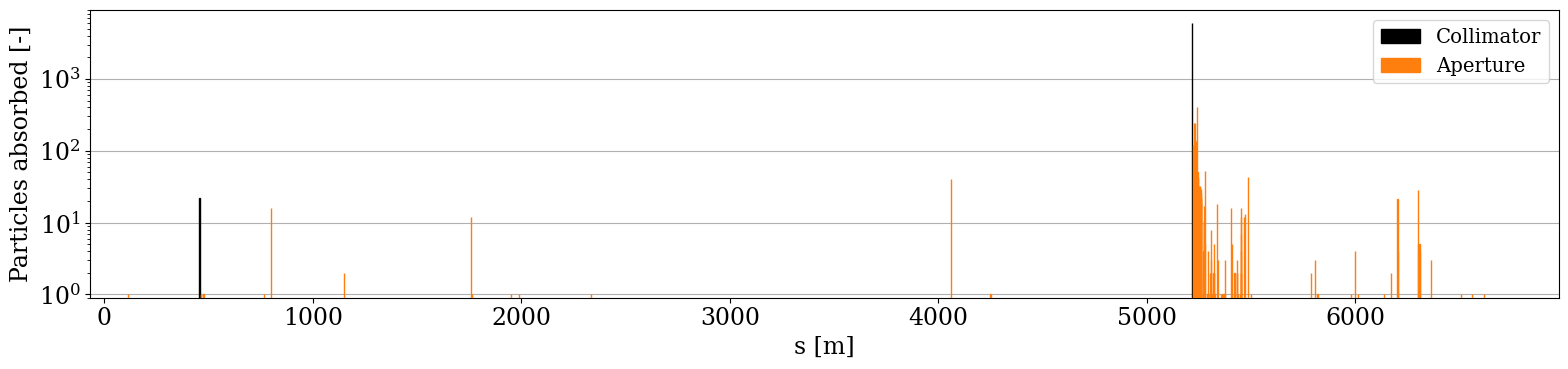

(<Figure size 1600x400 with 1 Axes>,
 <Axes: xlabel='s [m]', ylabel='Particles absorbed [-]'>)

In [13]:
ThisLM = xc.LossMap(line = line, line_is_reversed=False, part=part, interpolation=False)
ThisLM.plot(norm='raw')
# ThisLM.plot(savefig=f'plots/adt_ramping/LM_scheme1_10000part.png')


In [ ]:
ThisLM.aperture_losses

{'name': array(['vcak.12501.a_aper', 'vttb.13602.b_aper', 'veqa.21910.a_aper',
        'veqa.41910.a_aper', 'vcyc.51934.b_aper', 'vcal.51939.b_aper',
        'vcal.51956.b_aper', 'vbba.51974.b_aper', 'vcal.51974.b_aper',
        'vbba.51991.b_aper', 'vbba.51992.b_aper', 'vbba.51993.a_aper',
        'vcab.51994.b_aper', 'vcaa.51994.b_aper', 'vbbc.51998.a_aper',
        'vbbc.51998.b_aper', 'vttm.52002.a_aper', 'vttm.52002.b_aper',
        'vttm.52002.c_aper', 'vtte.52005.a_aper', 'vtte.52005.b_aper',
        'mdh.52007.a_aper', 'mdh.52007.b_aper', 'veqf.52010.b_aper',
        'veba.52030.a_aper', 'mba.52030..1_aper2', 'mba.52030..2_aper2',
        'mba.52030..3_aper2', 'mba.52030..4_aper2', 'mba.52030..5_aper2',
        'mba.52030..6_aper2', 'mba.52030..7_aper2', 'mba.52030..8_aper2',
        'mba.52030..9_aper2', 'mba.52030..10_aper2', 'veba.52030.b_aper',
        'mba.52050..0_aper2', 'mba.52050..1_aper2', 'mba.52050..2_aper2',
        'mba.52050..3_aper2', 'mba.52050..4_aper2', 'mba.

In [ ]:
np.unique(part.state, return_counts=True)

(array([-331,    0,    1]), array([591, 286, 123]))

In [ ]:
idx = line.element_names.index('vttm.52002.b_aper')
len(part.at_turn[part.at_element == idx])

48

In [ ]:
ThisLM.to_json(f'LM_phase_{phase}.json')

In [ ]:
# ThisLM.save_summary('new_version_summary.json')

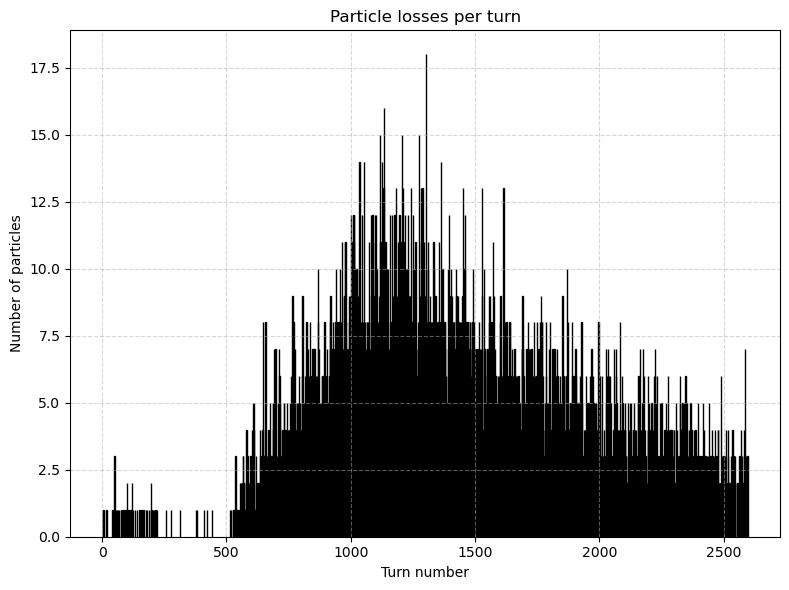

In [14]:
plt.close('all')
mask = part.state > 0
unique_turns, counts = np.unique(part.at_turn[~mask], return_counts=True)

fig, ax = plt.subplots(figsize=(8, 6))
# Plot histogram-like bar chart
ax.bar(unique_turns, counts, width=1.0, edgecolor='black')
ax.set_xlabel("Turn number")
ax.set_ylabel("Number of particles")
ax.set_title("Particle losses per turn")
ax.grid(True, linestyle='--', alpha=0.5)
fig.tight_layout()
# plt.savefig(f'plots/adt_ramping/scheme1_10000part.png', dpi=300)
plt.show()

In [15]:
np.unique(part.state, return_counts=True)

(array([-330,    0,    1]), array([6082, 2495, 1423]))

In [16]:
6082 + 2495

8577

In [ ]:
part2=part.copy()

In [ ]:
np.unique(part.at_element[part.state == 0])

array([ 3674,  5323,  8106, 18885, 24304, 24316, 24324, 24328, 24332,
       24336, 24344, 24348, 24354, 24358, 24372, 24374, 24379, 24381,
       24385, 24387, 24391, 24394, 24398, 24409, 24411, 24417, 24419,
       24421, 24423, 24425, 24427, 24429, 24431, 24433, 24435, 24439,
       24445, 24447, 24449, 24451, 24453, 24455, 24459, 24461, 24463,
       24465, 24471, 24525, 24531, 24553, 24609, 24686, 24740, 24746,
       24818, 24962, 25167, 25229, 25277, 25279, 25295, 25383, 25393,
       25459, 25495, 25555, 27108, 27171, 29029, 29045, 29426, 29459,
       29709])

In [ ]:
np.array(line.element_names)[[i for i in np.unique(part.at_element[part.state == 0])]]

array(['vcak.12501.a_aper', 'vttb.13602.b_aper', 'veqa.21910.a_aper',
       'veqa.41910.a_aper', 'vcyc.51934.b_aper', 'vcal.51939.b_aper',
       'vcal.51956.b_aper', 'vbba.51974.b_aper', 'vcal.51974.b_aper',
       'vbba.51991.b_aper', 'vbba.51992.b_aper', 'vbba.51993.a_aper',
       'vcab.51994.b_aper', 'vcaa.51994.b_aper', 'vbbc.51998.a_aper',
       'vbbc.51998.b_aper', 'vttm.52002.a_aper', 'vttm.52002.b_aper',
       'vttm.52002.c_aper', 'vtte.52005.a_aper', 'vtte.52005.b_aper',
       'mdh.52007.a_aper', 'mdh.52007.b_aper', 'veqf.52010.b_aper',
       'veba.52030.a_aper', 'mba.52030..1_aper2', 'mba.52030..2_aper2',
       'mba.52030..3_aper2', 'mba.52030..4_aper2', 'mba.52030..5_aper2',
       'mba.52030..6_aper2', 'mba.52030..7_aper2', 'mba.52030..8_aper2',
       'mba.52030..9_aper2', 'mba.52030..10_aper2', 'veba.52030.b_aper',
       'mba.52050..0_aper2', 'mba.52050..1_aper2', 'mba.52050..2_aper2',
       'mba.52050..3_aper2', 'mba.52050..4_aper2', 'mba.52050..5_aper2',
     

In [ ]:
tt.rows['vcak.12501.a_aper<<10':'vcak.12501.a_aper>>10']

LineTable: 21 rows, 13 cols
name                              s element_type       isthick isreplica parent_name        ...
mbb.12490..8_aper2          796.348 LimitRect            False     False None              
mbb.12490..8                796.348 ThickSliceRBend       True     False mbb.12490         
mbb.12490..9_aper2          796.974 LimitRect            False     False None              
mbb.12490..9                796.974 ThickSliceRBend       True     False mbb.12490         
mbb.12490..10_aper2           797.6 LimitRect            False     False None              
mbb.12490..exit_map           797.6 ThinSliceRBendExit   False     False mbb.12490         
mbb.12490_exit                797.6 Marker               False     False None              
drift_218..0                  797.6 DriftSlice            True     False drift_218         
vebb.12490.b_aper           797.795 LimitRect            False     False None              
drift_218..1                797.795 DriftSlice  

In [ ]:
tt.rows[(tt.s > 5241) & (tt.s < 5244)]

LineTable: 27 rows, 13 cols
name                              s element_type isthick isreplica parent_name        parent_type ...
drift_1444..0               5241.65 DriftSlice      True     False drift_1444         Drift      
vbbc.51998.a_aper           5241.65 LimitEllipse   False     False None               None       
drift_1444..1               5241.65 DriftSlice      True     False drift_1444         Drift      
vbbc.51998.b_aper           5241.78 LimitEllipse   False     False None               None       
drift_1444..2               5241.78 DriftSlice      True     False drift_1444         Drift      
drift_1444..3               5241.79 DriftSlice      True     False drift_1444         Drift      
drift_1445..0               5242.07 DriftSlice      True     False drift_1445         Drift      
drift_1445..1               5242.35 DriftSlice      True     False drift_1445         Drift      
vttm.52002.a_aper           5242.35 LimitEllipse   False     False None               

In [ ]:
ThisLM2 = xc.LossMap(line = line, line_is_reversed=False, part=part2, interpolation=0.1)

Performing the aperture losses refinement.
Compiling ContextCpu kernels...


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored


Done compiling ContextCpu kernels.
Compiling ContextCpu kernels...


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored


Done compiling ContextCpu kernels.


Slicing line:   0%|          | 0/2 [00:00<?, ?it/s]

... (12 outputs left out)

Slicing line:   0%|          | 0/4 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/4 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/4 [00:00<?, ?it/s]

TypeError: Cannot backtrack through element mdh.52007 of type Multipole

In [ ]:
line.check_aperture()

Checking aperture:   0%|          | 0/32241 [00:00<?, ?it/s]

Done checking aperture.           
1297 thin elements miss associated aperture (upstream):
['mba.10030..entry_map',
 'mba.10050..entry_map',
 'mbb.10070..entry_map',
 'mbb.10090..entry_map',
 'mdv.10107',
 'mbb.10130..entry_map',
 'mbb.10150..entry_map',
 'mba.10170..entry_map',
 'mba.10190..entry_map',
 'mdh.10207',
 'mba.10230..entry_map',
 'mba.10250..entry_map',
 'mbb.10270..entry_map',
 'mbb.10290..entry_map',
 'mdv.10307',
 'mbb.10330..entry_map',
 'mbb.10350..entry_map',
 'mba.10370..entry_map',
 'mba.10390..entry_map',
 'mdh.10407',
 'mba.10430..entry_map',
 'mba.10450..entry_map',
 'mbb.10470..entry_map',
 'mbb.10490..entry_map',
 'mdv.10507',
 'mbb.10530..entry_map',
 'mbb.10550..entry_map',
 'mba.10570..entry_map',
 'mba.10590..entry_map',
 'lse.10602..entry_map',
 'lse.10602..exit_map',
 'mdh.10607',
 'mba.10630..entry_map',
 'mba.10650..entry_map',
 'mbb.10670..entry_map',
 'mbb.10690..entry_map',
 'mdv.10707',
 'mbb.10730..entry_map',
 'mbb.10750..entry_map',
 'mba.10770.

,s,element_type,name,isthick,isreplica,parent_name,parent_type,prototype,iscollective,s_start,...,s_end,element,is_aperture,i_aperture_upstream,s_aperture_upstream,i_aperture_downstream,s_aperture_downstream,misses_aperture_upstream,misses_aperture_downstream,has_aperture_problem
0,0.0000,Marker,sps$start,False,False,None,None,None,False,0.0000,...,0.0000,Marker(),False,NaN,NaN,NaN,NaN,False,False,False
1,0.0000,Marker,begi.10010,False,False,None,None,None,False,0.0000,...,0.0000,Marker(),False,NaN,NaN,NaN,NaN,False,False,False
2,0.0000,Quadrupole,qf.10010,True,False,None,None,None,False,0.0000,...,3.0850,"Quadrupole(k1=0.0116, k1s=0, length=3.08, num_...",False,NaN,NaN,NaN,NaN,False,False,False
3,3.0850,DriftSlice,drift_0..0,True,False,drift_0,Drift,None,False,3.0850,...,3.2504,"DriftSlice(parent_name='drift_0', radiation_fl...",False,NaN,NaN,NaN,NaN,False,False,False
4,3.2504,LimitEllipse,veqf.10010.b_aper,False,False,None,None,None,False,3.2504,...,3.2504,"LimitEllipse(a=0.076, b=0.0208)",True,NaN,NaN,NaN,NaN,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32241,6908.0038,Drift,bph.63608,True,False,None,None,None,False,6908.0038,...,6908.2788,"Drift(length=0.275, model='adaptive')",False,NaN,NaN,NaN,NaN,False,False,False
32242,6908.2788,Drift,drift_1905,True,False,None,None,None,False,6908.2788,...,6908.3738,"Drift(length=0.095, model='adaptive')",False,NaN,NaN,NaN,NaN,False,False,False
32243,6908.3738,Marker,end.10010,False,False,None,None,None,False,6908.3738,...,6908.3738,Marker(),False,NaN,NaN,NaN,NaN,False,False,False
32244,6908.3738,Marker,sps$end,False,False,None,None,None,False,6908.3738,...,6908.3738,Marker(),False,NaN,NaN,NaN,NaN,False,False,False
